# BÀI 1 — MỨC ĐỘ IMBALANCE
Thay số mẫu **malignant** từ `60` thành `40`, `120` và toàn bộ dữ liệu gốc (212 mẫu). So sánh **Accuracy, Recall, F1 và PR-AUC**.

Dữ liệu: Breast Cancer Wisconsin (569 mẫu, 30 feature). Nhãn: `1 = malignant` (lớp cần phát hiện), `0 = benign`.
Quy trình giữ nguyên như bài thực hành: Train/Test split (`stratify=y`) → `Pipeline(StandardScaler + LogisticRegression)` → Stratified 5-Fold CV trên tập train → fit lại trên train → đánh giá một lần trên test.

## Bước 1. Import thư viện và nạp dữ liệu

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             make_scorer)

RANDOM_STATE = 42

cancer = load_breast_cancer(as_frame=True)
X_full = cancer.data.copy()
y_full = (cancer.target == 0).astype(int)   # 1 = malignant, 0 = benign

df_full = X_full.copy()
df_full["target"] = y_full
print("Kích thước dữ liệu gốc:", df_full.shape)
print(df_full["target"].value_counts().sort_index().rename({0: "Benign (0)", 1: "Malignant (1)"}))

Kích thước dữ liệu gốc: (569, 31)
target
Benign (0)       357
Malignant (1)    212
Name: count, dtype: int64


## Bước 2. Hàm tạo dữ liệu theo số mẫu malignant
Giữ toàn bộ mẫu `benign` (357), lấy ngẫu nhiên `n_malignant` mẫu malignant. Nếu `n_malignant=None` thì dùng toàn bộ 212 mẫu malignant.

In [2]:
def make_dataset(n_malignant):
    benign_df = df_full[df_full["target"] == 0]
    malignant_all = df_full[df_full["target"] == 1]
    if n_malignant is None:
        malignant_df = malignant_all
    else:
        malignant_df = malignant_all.sample(n=n_malignant, random_state=RANDOM_STATE)
    d = pd.concat([benign_df, malignant_df], axis=0)
    return d.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

scenarios = {
    "40 malignant": 40,
    "60 malignant (gốc)": 60,
    "120 malignant": 120,
    "Toàn bộ (212)": None,
}

rows = []
for name, n in scenarios.items():
    d = make_dataset(n)
    cnt = d["target"].value_counts().sort_index()
    rows.append({"Kịch bản": name, "Tổng mẫu": len(d), "Benign": cnt[0],
                 "Malignant": cnt[1],
                 "Malignant (%)": round(100 * cnt[1] / len(d), 2),
                 "Tỷ lệ Benign:Malignant": round(cnt[0] / cnt[1], 2)})
class_table = pd.DataFrame(rows).set_index("Kịch bản")
display(class_table)

                    Tổng mẫu  Benign  Malignant  Malignant (%)  Tỷ lệ Benign:Malignant
Kịch bản                                                                              
40 malignant             397     357         40          10.08                    8.93
60 malignant (gốc)       417     357         60          14.39                    5.95
120 malignant            477     357        120          25.16                    2.98
Toàn bộ (212)            569     357        212          37.26                    1.68


**Nhận xét:** càng nhiều malignant thì tỷ lệ minority càng tăng (từ ~10% lên ~37%), mức imbalance giảm dần: tỷ lệ Benign:Malignant giảm từ ~8.9:1 xuống ~1.7:1.

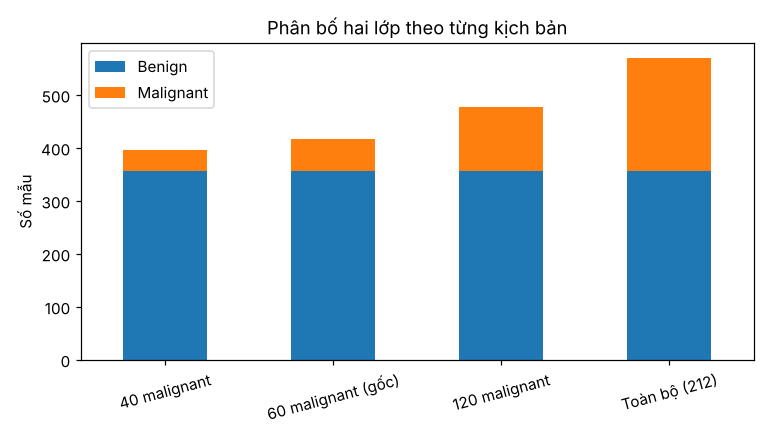

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
class_table[["Benign", "Malignant"]].plot(kind="bar", stacked=True, ax=ax)
ax.set_title("Phân bố hai lớp theo từng kịch bản")
ax.set_ylabel("Số mẫu")
ax.set_xlabel("")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## Bước 3. Thiết lập metric, pipeline và hàm đánh giá

In [4]:
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
}

def build_pipeline():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
    ])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def run_scenario(n_malignant):
    d = make_dataset(n_malignant)
    X, y = d.drop(columns="target"), d["target"]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

    # Dummy baseline: luôn đoán lớp đa số
    dummy_cv = cross_validate(DummyClassifier(strategy="most_frequent"),
                              X_train, y_train, cv=skf, scoring=scoring)
    dummy_acc = dummy_cv["test_accuracy"].mean()

    # Cross validation trên tập train
    cv = cross_validate(build_pipeline(), X_train, y_train, cv=skf, scoring=scoring)
    cv_mean = {m: cv[f"test_{m}"].mean() for m in scoring}
    cv_std = {m: cv[f"test_{m}"].std() for m in scoring}

    # Fit lại trên toàn bộ train, đánh giá một lần trên test
    model = build_pipeline().fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    test = {
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred, zero_division=0),
        "f1": f1_score(y_test, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, y_prob),
        "pr_auc": average_precision_score(y_test, y_prob),
    }
    return {"n_train": len(y_train), "n_test": len(y_test),
            "train_malignant": int(y_train.sum()), "test_malignant": int(y_test.sum()),
            "dummy_acc": dummy_acc, "cv_mean": cv_mean, "cv_std": cv_std, "test": test}

## Bước 4. Chạy 4 kịch bản

In [5]:
results = {name: run_scenario(n) for name, n in scenarios.items()}

split_info = pd.DataFrame({
    name: {"Train": r["n_train"], "Train malignant": r["train_malignant"],
           "Test": r["n_test"], "Test malignant": r["test_malignant"]}
    for name, r in results.items()
}).T
display(split_info)

                    Train  Train malignant  Test  Test malignant
40 malignant          317               32    80               8
60 malignant (gốc)    333               48    84              12
120 malignant         381               96    96              24
Toàn bộ (212)         455              170   114              42


## Bước 5. Kết quả Cross Validation (Stratified 5-Fold trên tập train)
Đây là kết quả dùng để so sánh các kịch bản (tập test chưa được dùng để chọn gì).

In [6]:
metrics = ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]

cv_table = pd.DataFrame({name: r["cv_mean"] for name, r in results.items()}).T[metrics]
cv_table.insert(0, "Dummy Acc", [r["dummy_acc"] for r in results.values()])
display(cv_table.round(4))

print("\nStandard deviation giữa các fold:")
cv_std_table = pd.DataFrame({name: r["cv_std"] for name, r in results.items()}).T[metrics]
display(cv_std_table.round(4))

                    Dummy Acc  accuracy  precision  recall      f1  roc_auc  pr_auc
40 malignant           0.8991    0.9938     1.0000  0.9429  0.9692   0.9940  0.9754
60 malignant (gốc)     0.8559    0.9850     0.9618  0.9400  0.9447   0.9951  0.9855
120 malignant          0.7481    0.9711     0.9636  0.9274  0.9432   0.9915  0.9882
Toàn bộ (212)          0.6264    0.9758     0.9825  0.9529  0.9668   0.9945  0.9939

Standard deviation giữa các fold:
                    accuracy  precision  recall      f1  roc_auc  pr_auc
40 malignant          0.0077     0.0000  0.0700  0.0377   0.0088  0.0324
60 malignant (gốc)    0.0164     0.0469  0.1200  0.0646   0.0098  0.0291
120 malignant         0.0193     0.0727  0.0246  0.0347   0.0126  0.0131
Toàn bộ (212)         0.0108     0.0143  0.0399  0.0158   0.0058  0.0049


## Bước 6. Kết quả trên tập test (đánh giá một lần)

In [7]:
test_table = pd.DataFrame({name: r["test"] for name, r in results.items()}).T[metrics]
display(test_table.round(4))

                    accuracy  precision  recall      f1  roc_auc  pr_auc
40 malignant          1.0000     1.0000  1.0000  1.0000   1.0000  1.0000
60 malignant (gốc)    0.9881     1.0000  0.9167  0.9565   0.9988  0.9936
120 malignant         0.9688     0.9565  0.9167  0.9362   0.9664  0.9567
Toàn bộ (212)         0.9649     0.9750  0.9286  0.9512   0.9914  0.9888


## Bước 7. Trực quan hóa

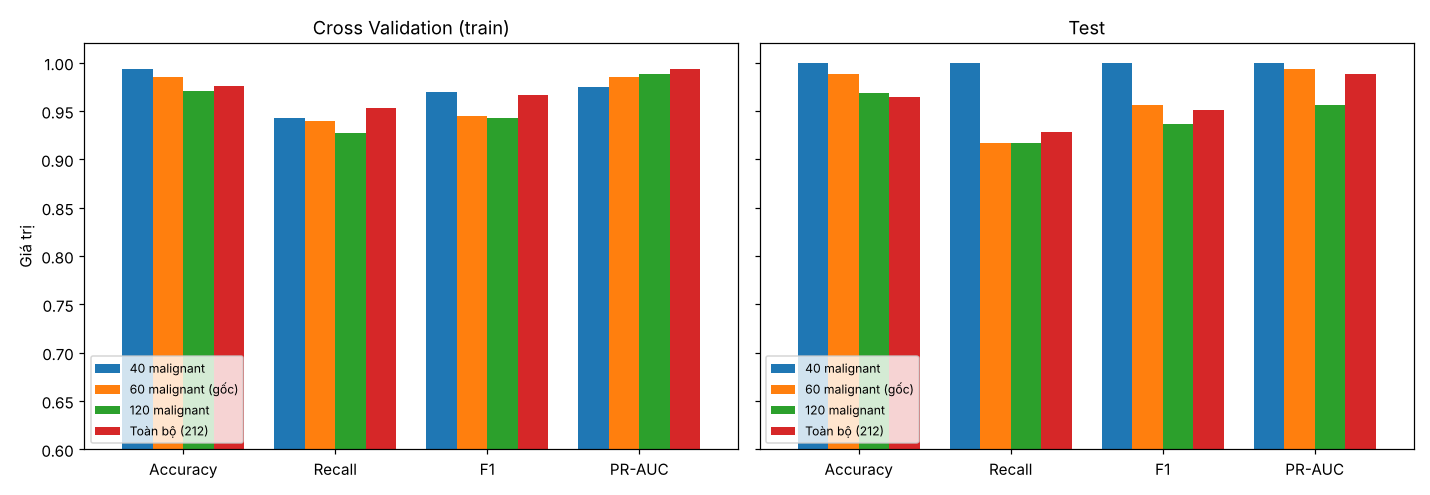

In [8]:
key = ["accuracy", "recall", "f1", "pr_auc"]
labels = ["Accuracy", "Recall", "F1", "PR-AUC"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, tbl, title in zip(axes, [cv_table[key], test_table[key]],
                          ["Cross Validation (train)", "Test"]):
    tbl.T.set_index(pd.Index(labels)).plot(kind="bar", ax=ax, width=0.8)
    ax.set_title(title)
    ax.set_ylim(0.6, 1.02)
    ax.set_ylabel("Giá trị")
    ax.tick_params(axis="x", rotation=0)
    ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

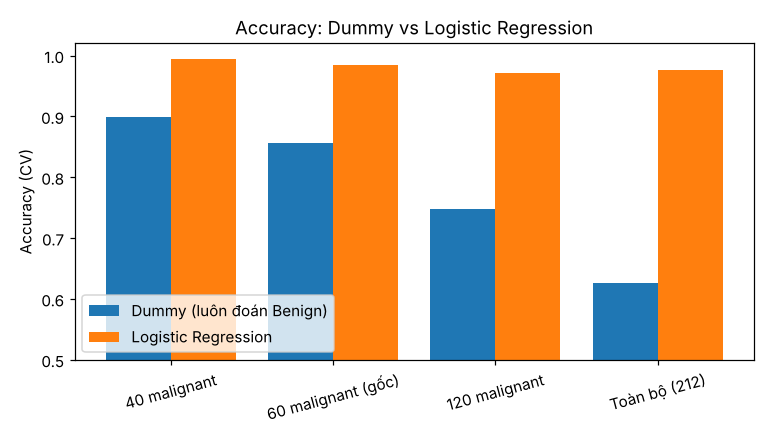

In [9]:
# Accuracy của Dummy (luôn đoán Benign) và của Logistic Regression
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(cv_table))
ax.bar(x - 0.2, cv_table["Dummy Acc"], 0.4, label="Dummy (luôn đoán Benign)")
ax.bar(x + 0.2, cv_table["accuracy"], 0.4, label="Logistic Regression")
ax.set_xticks(x); ax.set_xticklabels(cv_table.index, rotation=15)
ax.set_ylim(0.5, 1.02); ax.set_ylabel("Accuracy (CV)")
ax.set_title("Accuracy: Dummy vs Logistic Regression")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

## Bước 8. Nhận xét

### Nhận xét kết quả (dựa trên Cross Validation trên tập train)

**1. Accuracy bị "thổi phồng" khi imbalance nặng.**
Baseline Dummy (luôn đoán Benign) đạt Accuracy 0.899 → 0.856 → 0.748 → 0.626 khi số malignant tăng 40 → 60 → 120 → 212. Logistic Regression luôn đạt 0.97–0.99, nhưng phần vượt trội so với Dummy chỉ là +0.095 (40 malignant) so với +0.350 (toàn bộ). Vì vậy ở kịch bản 40 malignant, Accuracy 0.9938 trông đẹp nhưng phần lớn đến từ lớp đa số; Accuracy không phản ánh khả năng phát hiện malignant.

**2. Recall và F1 không thay đổi theo một chiều rõ ràng.**
Recall: 0.943 / 0.940 / 0.927 / 0.953; F1: 0.969 / 0.945 / 0.943 / 0.967. Chênh lệch nhỏ hơn độ lệch chuẩn giữa các fold (Recall std 0.070 / 0.120 / 0.025 / 0.040), nên không thể kết luận "nhiều malignant hơn thì Recall tốt hơn". Điểm đáng chú ý là độ dao động: khi minority ít (40 và 60 mẫu, mỗi fold validation chỉ có ~6–10 mẫu malignant) Recall thay đổi rất mạnh giữa các fold (std 0.07–0.12); khi dùng toàn bộ dữ liệu std giảm còn 0.040.

**3. PR-AUC tăng đều và ổn định dần.**
PR-AUC: 0.9754 → 0.9855 → 0.9882 → 0.9939, std giảm 0.0324 → 0.0291 → 0.0131 → 0.0049. Lưu ý: PR-AUC của một mô hình ngẫu nhiên bằng tỷ lệ lớp dương (10% → 37%), nên một phần mức tăng đến từ việc baseline cao hơn; không nên đọc đây là mô hình "giỏi hơn" một cách tuyệt đối.

**4. Kết quả trên tập test chỉ mang tính tham khảo.**
Test chỉ có 8 / 12 / 24 / 42 mẫu malignant nên một vài mẫu sai làm Recall đổi rất nhiều (ví dụ 8/8 mẫu đúng ở kịch bản 40 cho Recall = 1.0). Việc so sánh nên dựa vào CV (nhiều fold) và nhìn cả độ lệch chuẩn.

**Kết luận:** khi dữ liệu càng mất cân bằng, Accuracy càng kém tin cậy và các metric của lớp thiểu số (Recall, F1, PR-AUC) càng dao động mạnh giữa các fold. Cần báo cáo Recall/F1/PR-AUC kèm std, không chỉ Accuracy.